# Part 6c: do our numbers agree with independent published ones?

A model can be internally consistent and still wrong. This notebook checks our state measures and our expiring-unit counts against published figures from other organizations that built theirs differently.

**State measures against NLIHC's The Gap** (state table on https://nlihc.org/gap, copied 2026-10-11; `data/raw/nlihc_gap/`). NLIHC uses the American Community Survey microdata; we use HUD's CHAS tabulation. Three comparisons: the number of extremely low income (ELI) renter households, affordable homes per 100 of them (NLIHC counts homes that are affordable **and available**, ours counts affordable homes, so ours is higher by construction and only the ordering is comparable), and the share with severe cost burden.

**Expiring-unit counts against published ones:** the National Low Income Housing Coalition and Public and Affordable Housing Research Corporation (2024), a paper that uses NHPD with ACS tract data (Subedi and Wijekularathna, 2025), and a Chicago Fed Letter on LIHTC expirations (October 2025). All three use the same NHPD source with different snapshots and definitions, so agreement is expected within a range, not exactly.

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from viz import apply_style, SERIES, save_figure, BASELINE, INK_2, dot

apply_style()
pd.set_option("display.width", 220)
n = pd.read_csv("data/interim/nlihc_gap_state.csv", dtype={"state_fips": str})
sc = pd.read_csv("outputs/tables/scenarios_state.csv", dtype={"state_fips": str})
b = sc[(sc.scenario == "baseline") & (sc.year == 2023)][["state_fips", "eli_renters", "afford_units"]]
a = pd.read_csv("outputs/tables/ahni_ranking.csv", dtype={"state_fips": str})[["state_fips", "ahni_score", "ahni_rank", "severe_burden_chas_le50"]]
d = n.merge(b, on="state_fips").merge(a, on="state_fips")
d["ours_per100"] = 100 * d.afford_units / d.eli_renters
d["eli_ratio"] = d.eli_renters / d.nlihc_eli_renters

## 1. State measures against NLIHC

In [2]:
rows = [
    ("ELI renter households (level)", "pearson", d.eli_renters.corr(d.nlihc_eli_renters)),
    ("ELI renter households (level)", "spearman", d.eli_renters.corr(d.nlihc_eli_renters, method="spearman")),
    ("affordable units per 100 ELI renters (ours: affordable; NLIHC: affordable and available)", "spearman", d.ours_per100.corr(d.nlihc_affordable_available_per100, method="spearman")),
    ("affordable units per 100 ELI renters", "pearson", d.ours_per100.corr(d.nlihc_affordable_available_per100)),
    ("severe cost burden (ours: renters at or below 50% of area median; NLIHC: ELI renters)", "spearman", d.severe_burden_chas_le50.corr(d.nlihc_eli_severe_burden_pct, method="spearman")),
    ("our need index against NLIHC homes per 100 (expect negative)", "spearman", d.ahni_score.corr(d.nlihc_affordable_available_per100, method="spearman")),
    ("our need index against NLIHC severe burden", "spearman", d.ahni_score.corr(d.nlihc_eli_severe_burden_pct, method="spearman")),
]
cmp_ = pd.DataFrame(rows, columns=["comparison", "statistic", "value"])
display(cmp_.round(3))
print(f"national ELI renter households: ours {d.eli_renters.sum() / 1e6:.2f} million, NLIHC {d.nlihc_eli_renters.sum() / 1e6:.2f} million; state ratio ours/NLIHC median {d.eli_ratio.median():.2f}, range {d.eli_ratio.min():.2f} to {d.eli_ratio.max():.2f}")
print("largest state gaps in ELI renters (ours/NLIHC):", ", ".join(f"{r.state_n if 'state_n' in d else r.state} {r.eli_ratio:.2f}" for r in d.loc[(d.eli_ratio - 1).abs().nlargest(5).index].itertuples()))
lowest = d.nsmallest(5, "ours_per100").state.tolist(); lowest_n = d.nsmallest(5, "nlihc_affordable_available_per100").state.tolist()
st = pd.read_csv("outputs/tables/units_at_stake_state.csv", dtype={"state_fips": str})[["state_fips", "stake_mid", "stake_per100_eli"]].merge(d[["state_fips", "state", "nlihc_eli_renters"]], on="state_fips")
st["per100_nlihc_denominator"] = 100 * st.stake_mid / st.nlihc_eli_renters
print("units at stake per 100 ELI renters, our denominator:", ", ".join(f"{r.state} {r.stake_per100_eli:.0f}" for r in st.nlargest(5, "stake_per100_eli").itertuples()), "| NLIHC denominator:", ", ".join(f"{r.state} {r.per100_nlihc_denominator:.0f}" for r in st.nlargest(5, "per100_nlihc_denominator").itertuples()))
print("five lowest states, ours:", lowest, "| NLIHC:", lowest_n, "| overlap", len(set(lowest) & set(lowest_n)))
high_a = set(d.nlargest(10, "ahni_score").state); high_n = set(d.nsmallest(10, "nlihc_affordable_available_per100").state)
print(f"our top-10 need states against NLIHC's ten lowest-supply states: {len(high_a & high_n)} in common ({sorted(high_a & high_n)})")
d.to_csv("outputs/tables/benchmarks_state.csv", index=False)
cmp_.to_csv("outputs/tables/benchmarks_state_correlations.csv", index=False)

,comparison,statistic,value
0,ELI renter households (level),pearson,0.995
1,ELI renter households (level),spearman,0.995
2,affordable units per 100 ELI renters (ours: af...,spearman,0.751
3,affordable units per 100 ELI renters,pearson,0.827
4,severe cost burden (ours: renters at or below ...,spearman,0.743
5,our need index against NLIHC homes per 100 (ex...,spearman,-0.598
6,our need index against NLIHC severe burden,spearman,0.628


national ELI renter households: ours 10.92 million, NLIHC 11.03 million; state ratio ours/NLIHC median 0.96, range 0.79 to 1.13
largest state gaps in ELI renters (ours/NLIHC): Idaho 0.79, South Carolina 0.85, New Jersey 1.13, New Mexico 0.87, Oklahoma 0.87
units at stake per 100 ELI renters, our denominator: Idaho 26, South Dakota 21, Utah 18, New Hampshire 16, North Carolina 16 | NLIHC denominator: South Dakota 21, Idaho 21, Utah 19, Maine 15, New Hampshire 15
five lowest states, ours: ['Nevada', 'California', 'Florida', 'Texas', 'Colorado'] | NLIHC: ['Nevada', 'Oregon', 'California', 'Arizona', 'Florida'] | overlap 3
our top-10 need states against NLIHC's ten lowest-supply states: 6 in common (['Arizona', 'California', 'Colorado', 'Florida', 'Nevada', 'Oregon'])


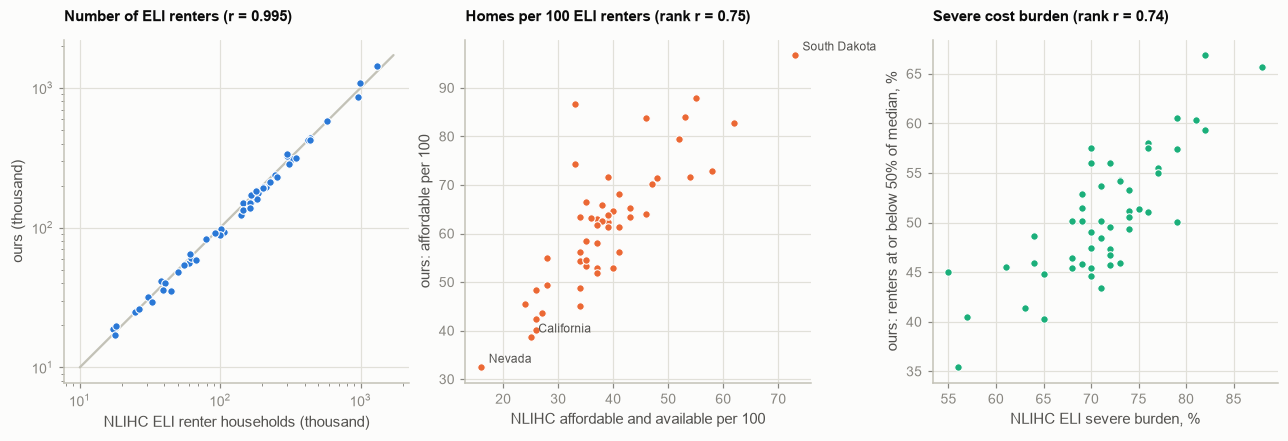

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(11.6, 3.9))
ax = axs[0]
ax.scatter(d.nlihc_eli_renters / 1e3, d.eli_renters / 1e3, s=24, color=SERIES[0], edgecolor="white", linewidth=0.7, zorder=3)
lim = [10, 1.2 * max(d.nlihc_eli_renters.max(), d.eli_renters.max()) / 1e3]
ax.plot(lim, lim, color=BASELINE, lw=1.5); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("NLIHC ELI renter households (thousand)"); ax.set_ylabel("ours (thousand)")
ax.set_title(f"Number of ELI renters (r = {d.eli_renters.corr(d.nlihc_eli_renters):.3f})", fontsize=9.5, loc="left")
ax = axs[1]
ax.scatter(d.nlihc_affordable_available_per100, d.ours_per100, s=24, color=SERIES[1], edgecolor="white", linewidth=0.7, zorder=3)
for nm in ("Nevada", "California", "South Dakota"):
    r = d[d.state == nm].iloc[0]
    ax.annotate(nm, (r.nlihc_affordable_available_per100, r.ours_per100), xytext=(5, 3), textcoords="offset points", fontsize=8, color=INK_2)
ax.set_xlabel("NLIHC affordable and available per 100"); ax.set_ylabel("ours: affordable per 100")
ax.set_title(f"Homes per 100 ELI renters (rank r = {d.ours_per100.corr(d.nlihc_affordable_available_per100, method='spearman'):.2f})", fontsize=9.5, loc="left")
ax = axs[2]
ax.scatter(d.nlihc_eli_severe_burden_pct, d.severe_burden_chas_le50, s=24, color=SERIES[2], edgecolor="white", linewidth=0.7, zorder=3)
ax.set_xlabel("NLIHC ELI severe burden, %"); ax.set_ylabel("ours: renters at or below 50% of median, %")
ax.set_title(f"Severe cost burden (rank r = {d.severe_burden_chas_le50.corr(d.nlihc_eli_severe_burden_pct, method='spearman'):.2f})", fontsize=9.5, loc="left")
save_figure(fig, "64_nlihc_comparison", part="06_combined")
plt.show()

## 2. Expiring units against published counts

Our counts come from the same NHPD (October 2026 snapshot). The lower bound counts the largest active subsidy at each property; the upper bound the property's total units (assisted and unassisted).

In [4]:
ne = pd.read_csv("data/interim/nhpd_expiry_state.csv"); le = pd.read_csv("data/interim/lihtc_expiry_state.csv")
subs = pd.read_csv("data/interim/nhpd_subsidies.csv.gz", usecols=["program", "status", "end_year", "assisted_units"])
lih = subs[(subs.program == "LIHTC") & (subs.status == "Active") & subs.end_year.notna()]
nhpd_lihtc_share = lih[lih.end_year <= 2035].assisted_units.sum() / lih.assisted_units.sum()
hud_share = le.lihtc_units_est_end_by_2035.sum() / le.lihtc_units_monitored.sum()
hud_share_incl = (le.lihtc_units_est_end_by_2035.sum() + le.lihtc_units_monitored_past_est_end.sum()) / le.lihtc_units_monitored.sum()
pub = pd.DataFrame([
    {"source": "NLIHC and PAHRC, Picture of Preservation 2024 (Dec 2024)", "published": "374,497 federally assisted homes with restrictions expiring in the next five years (7% of about 5 million)",
     "ours": f"{ne.nhpd_last_end_by_2030_units_lb.sum():,.0f} to {ne.nhpd_last_end_by_2030_units_ub.sum():,.0f} units whose last subsidy ends 2026-2030 (lower to upper bound); {ne.nhpd_first_end_by_2030_units_lb.sum():,.0f} to {ne.nhpd_first_end_by_2030_units_ub.sum():,.0f} if the first subsidy ending counts",
     "reading": "published figure falls inside our 'last subsidy ends' range"},
    {"source": "Subedi and Wijekularathna (2025), NHPD with ACS tracts (baseline April 2025)", "published": "10,986 properties and 496,766 units with a primary subsidy ending within five years (by 2030)",
     "ours": f"{ne.nhpd_last_end_by_2030_props.sum():,.0f} properties and up to {ne.nhpd_last_end_by_2030_units_ub.sum():,.0f} units whose last subsidy ends by 2030",
     "reading": f"ours is {ne.nhpd_last_end_by_2030_props.sum() / 10986:.0%} of their properties and {ne.nhpd_last_end_by_2030_units_ub.sum() / 496766:.0%} of their units; they use the property file's latest end date, which we found unreliable"},
    {"source": "Chicago Fed Letter 514 (Oct 2025), NHPD December 2023", "published": "about one third (34%) of 2.47 million active LIHTC units scheduled to expire by 2035; about 41% with early exits",
     "ours": f"{100 * nhpd_lihtc_share:.0f}% of active LIHTC units in NHPD end by 2035; {100 * hud_share:.0f}% of the HUD database's {le.lihtc_units_monitored.sum() / 1e6:.2f} million monitored units ({100 * hud_share_incl:.0f}% counting units already past their estimated end)",
     "reading": "the HUD-database range (31% to 38%) brackets their 34%; the NHPD share is lower (25%) because units that expired in 2024 and 2025 have already left the active set in our later snapshot"},
    {"source": "NLIHC and PAHRC 2024; Chicago Fed 2025", "published": "155,555 LIHTC units (8.8% of units placed through 2008) have exited through the qualified-contract process since 1990",
     "ours": "not comparable: our outcome is leaving the monitoring list for any reason (expiry, qualified contract, other); the reason field is filled for only 406 projects",
     "reading": "cannot be reproduced; we do not split exits by cause"},
    {"source": "Harvard JCHS household projections 2025-2035", "published": "not retrieved: the page sits behind a bot check, so no figure is quoted", "ours": "our renter-household projection is not a total-household projection", "reading": "no comparison made"},
])
pub.to_csv("outputs/tables/benchmarks_published_counts.csv", index=False)
with pd.option_context("display.max_colwidth", 200):
    display(pub)

,source,published,ours,reading
0,"NLIHC and PAHRC, Picture of Preservation 2024 (Dec 2024)","374,497 federally assisted homes with restrictions expiring in the next five years (7% of about 5 million)","336,603 to 406,979 units whose last subsidy ends 2026-2030 (lower to upper bound); 621,401 to 705,370 if the first subsidy ending counts",published figure falls inside our 'last subsidy ends' range
1,"Subedi and Wijekularathna (2025), NHPD with ACS tracts (baseline April 2025)","10,986 properties and 496,766 units with a primary subsidy ending within five years (by 2030)","9,244 properties and up to 406,979 units whose last subsidy ends by 2030","ours is 84% of their properties and 82% of their units; they use the property file's latest end date, which we found unreliable"
2,"Chicago Fed Letter 514 (Oct 2025), NHPD December 2023",about one third (34%) of 2.47 million active LIHTC units scheduled to expire by 2035; about 41% with early exits,25% of active LIHTC units in NHPD end by 2035; 31% of the HUD database's 3.25 million monitored units (38% counting units already past their estimated end),the HUD-database range (31% to 38%) brackets their 34%; the NHPD share is lower (25%) because units that expired in 2024 and 2025 have already left the active set in our later snapshot
3,NLIHC and PAHRC 2024; Chicago Fed 2025,"155,555 LIHTC units (8.8% of units placed through 2008) have exited through the qualified-contract process since 1990","not comparable: our outcome is leaving the monitoring list for any reason (expiry, qualified contract, other); the reason field is filled for only 406 projects",cannot be reproduced; we do not split exits by cause
4,Harvard JCHS household projections 2025-2035,"not retrieved: the page sits behind a bot check, so no figure is quoted",our renter-household projection is not a total-household projection,no comparison made


## Findings

**Our state measures agree with NLIHC's.** The number of ELI renter households correlates 0.995 across states (10.92 million nationally against NLIHC's 11.03; state ratios 0.79 to 1.13, median 0.96). Affordable homes per 100 ELI renters ranks states similarly (Spearman 0.75; ours is higher in level because it counts affordable, not affordable and available, homes), with Nevada, California, and Florida among the lowest in both. Severe cost burden ranks alike (Spearman 0.74). Our need index runs opposite NLIHC's supply measure (Spearman -0.60) and with its severe-burden measure (+0.63); six of our ten highest-need states are among NLIHC's ten lowest-supply states (Arizona, California, Colorado, Florida, Nevada, Oregon). Two independent methods, two data products, one picture.

**Expiring-unit counts bracket the published ones.** The 374,497 federally assisted homes that NLIHC and PAHRC say expire within five years fall inside our 336,603 to 406,979 (last subsidy ends 2026 to 2030). A 2025 paper using the same database counted 10,986 properties and 496,766 units by 2030; ours are 84 and 82 percent of those, which fits their use of the property file's own end date, the field we found unreliable. For LIHTC, the Chicago Fed's one-third of active units expiring by 2035 sits inside our 31 to 38 percent from the HUD database; the NHPD-only share is lower (25 percent) because units expiring in 2024 and 2025 have already left the active set in a later snapshot.

**Two things the comparison exposes.** First, the ELI renter denominator matters for one headline sentence: Idaho's count is 21 percent below NLIHC's, and with NLIHC's counts as the denominator, South Dakota and Idaho tie at 21 units at stake per 100 ELI renters, with Utah third at 19 (ours: Idaho 26, South Dakota 21, Utah 18). The top three states are unchanged, the order is not firm. Second, we cannot reproduce NLIHC's early-exit count (155,555 LIHTC units through the qualified-contract process), because our outcome is leaving the monitoring list for any reason and the reason field is filled for only 406 projects.

**Not done.** The Harvard Joint Center household projections sit behind a bot check and were not retrieved, so no comparison is made. The NLIHC page does not state its survey year on the table; the comparison is to the table as displayed on 2026-10-11 (`data/raw/nlihc_gap/SOURCE.txt`).